# Figure 3: native versus admixed transcript localization

Localization of the **whole-gene donor-pool fraction λmax = 0.25** simulated test transcripts. Both populations have simulated locations: **Native** means the original clean scRNA-seq counts placed inside mapped cell masks; **Admixed** means the saved added counts, placed preferentially toward their known donor. This notebook does not compare with measured real-CosMx transcript locations.

As in `Figure1_SpilloverLocalization.ipynb`, each histogram observation is **one cell's mean transcript-to-boundary distance**, divided by its area-equivalent radius, computed separately for each population. Zero is the recipient boundary; larger values indicate deeper localization. Here all genes are included and labels come from simulation ground truth rather than marker-gene annotations. Cells with both populations are used, so native and admixed histograms describe the same paired cells.


In [1]:
from pathlib import Path
import sys

REPO = Path.cwd().resolve()
if not (REPO / "scripts/spillover-benchmark").is_dir():
    REPO = REPO.parent
if not (REPO / "scripts/spillover-benchmark").is_dir():
    raise RuntimeError("Run this notebook from the repository root or its figures directory")
sys.path.insert(0, str(REPO / "scripts/spillover-benchmark"))

BENCHMARK_ROOT = REPO / "outputs/SyndriSIM_pool_fraction"
OUTPUT_DIR = REPO / "figures/outputs/Figure3_SyndriSIM_TranscriptLocalization"
SLICES = ["Lung12", "Lung13", "Lung9_Rep1", "Lung9_Rep2"]
N_CELLS_PER_SLICE = 1000  # Uniform sample among cells with both populations; None uses all.
CELL_TYPES = None  # All types; e.g. ["T CD4+", "T CD8+"] for T cells only.
RANDOM_SEED = 20261121
RECOMPUTE_SLICES = []  # e.g. ["Lung12"]; [] reuses matching cached summaries.
MAX_SLICE_WORKERS = 4
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## Distance metric and caching

For cell $i$, let $P_i$ be its segmentation region and $r_i = \sqrt{|P_i|/\pi}$ its equivalent radius in micrometers. For population $t$ (native or admixed), the histogram value is
\[
\overline d_{it}=\frac{1}{n_{it}}\sum_{k=1}^{n_{it}}\frac{\operatorname{dist}(x_{ik},\partial P_i)}{r_i}.
\]

Distances are calculated from the exposed edges of the original segmentation-mask pixels, using the saved image orientation, FOV offsets, and 0.18 µm pixel scale. Distance **to the boundary** is used, rather than distance to the filled cell region (which would be zero for every interior transcript).

The first calculation streams the large CSVs using only cell identifiers, admixture labels, and x–y coordinates. It retains per-cell sums and counts rather than hundreds of millions of transcript records. Transcript totals for sampled cells must exactly match the saved native and added counts. Later runs load cached summaries. Changing the selected slices, sample size, cell-type filter, or seed selects the matching cache automatically; changing plot styling does not require recalculation.


In [2]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
from transcript_localization import slice_localization


def compute_localization(slice_name):
    return slice_localization(
        BENCHMARK_ROOT, OUTPUT_DIR, slice_name,
        n_cells=N_CELLS_PER_SLICE, seed=RANDOM_SEED, cell_types=CELL_TYPES,
        recompute=slice_name in RECOMPUTE_SLICES,
    )

with ThreadPoolExecutor(max_workers=min(MAX_SLICE_WORKERS, len(SLICES))) as pool:
    tables = list(pool.map(compute_localization, SLICES))
cell_distances = pd.concat(tables, ignore_index=True)
cell_distances.to_csv(OUTPUT_DIR / "cell_distance_summaries.csv", index=False)

summary = cell_distances.groupby(["slice", "transcript_type"], observed=True).agg(
    cells=("assigned_cell", "size"),
    transcripts=("n_transcripts", "sum"),
    mean_normalized_distance=("mean_normalized_distance", "mean"),
    median_normalized_distance=("mean_normalized_distance", "median"),
    mean_distance_um=("mean_distance_um", "mean"),
)
summary.to_csv(OUTPUT_DIR / "localization_summary.csv")
display(summary)


Lung12: reusing cached localization summaries
Lung13: reusing cached localization summaries
Lung9_Rep1: reusing cached localization summaries
Lung9_Rep2: reusing cached localization summaries


cells  ...  mean_distance_um
slice      transcript_type         ...                  
Lung12     Admixed           1000  ...          1.187144
           Native            1000  ...          1.655321
Lung13     Admixed           1000  ...          1.108158
           Native            1000  ...          1.483029
Lung9_Rep1 Admixed           1000  ...          1.131184
           Native            1000  ...          1.538791
Lung9_Rep2 Admixed           1000  ...          1.161775
           Native            1000  ...          1.620771

[8 rows x 5 columns]

In [3]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_path = REPO.parent / "fonts/ARIAL.TTF"
if font_path.exists():
    font_manager.fontManager.addfont(font_path)
    mpl.rcParams["font.family"] = "Arial"
mpl.rcParams.update({
    "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "svg.fonttype": "none", "pdf.fonttype": 42,
})

COLORS = {"Native": "#999999", "Admixed": "#E41A1C"}
HISTOGRAM_ALPHA = 0.65
BIN_WIDTH = 0.025
POOLED_FIGSIZE = (2.4, 2.1)
SLICE_FIGSIZE = (7.5, 2.0)
PNG_DPI = 600

maximum = cell_distances.mean_normalized_distance.max()
upper = max(0.75, np.ceil(maximum / BIN_WIDTH) * BIN_WIDTH + BIN_WIDTH)
BINS = np.arange(0, upper + BIN_WIDTH / 2, BIN_WIDTH)


def localization_histogram(ax, data, title, xlabel=True, ylabel=True):
    for kind in ["Native", "Admixed"]:
        values = data.loc[data.transcript_type.eq(kind), "mean_normalized_distance"].to_numpy()
        ax.hist(values, bins=BINS, weights=np.full(len(values), 1 / len(values)),
                color=COLORS[kind], label=kind, alpha=HISTOGRAM_ALPHA, linewidth=0)
    ax.set_xlim(0, BINS[-1])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Mean transcript distance to boundary\n(normalized by equivalent cell radius)" if xlabel else "", fontsize=8)
    ax.set_ylabel("Fraction of cells" if ylabel else "", fontsize=8)
    ax.tick_params(axis="both", labelsize=8, labelleft=ylabel)
    ax.spines[["top", "right"]].set_visible(False)


def save_figure(fig, stem):
    for suffix in ["svg", "pdf", "png"]:
        fig.savefig(OUTPUT_DIR / f"{stem}.{suffix}", dpi=PNG_DPI, bbox_inches="tight")


## Pooled histogram

Every sampled cell contributes one value to each population. With 1,000 sampled cells per slice, all four slices have equal weight. Within each population, bar heights sum to one. This matches Figure 1's per-cell summary, rather than weighting cells by their number of transcripts.


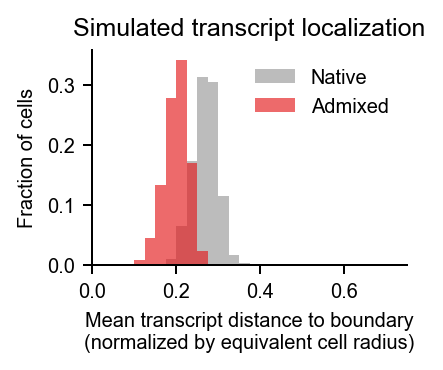

In [4]:
fig, ax = plt.subplots(figsize=POOLED_FIGSIZE, dpi=180)
localization_histogram(ax, cell_distances, "Simulated transcript localization")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "Figure3_native_vs_admixed_localization_pooled")
plt.show()


## Histograms by test slice

The same bin edges and y-axis range are used for every slice. Native and admixed distributions use the identical sampled recipient cells within each panel.


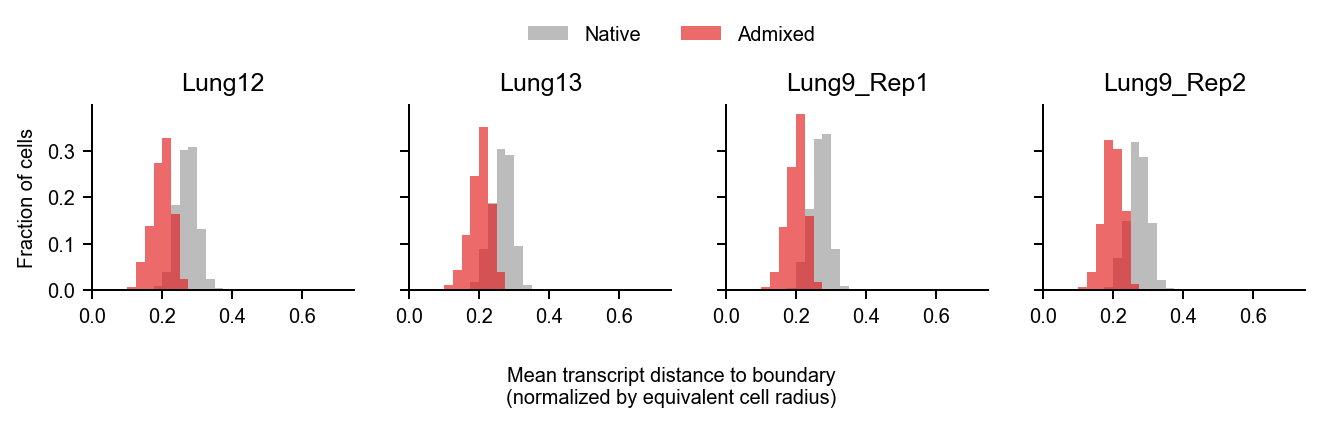

In [5]:
fig, axes = plt.subplots(1, len(SLICES), figsize=SLICE_FIGSIZE,
                         sharex=True, sharey=True, squeeze=False, dpi=180)
for column, (slice_name, ax) in enumerate(zip(SLICES, axes[0])):
    data = cell_distances.loc[cell_distances.slice.eq(slice_name)]
    localization_histogram(ax, data, slice_name, xlabel=False, ylabel=(column == 0))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.12),
           ncol=2, frameon=False, fontsize=8)
fig.supxlabel("Mean transcript distance to boundary\n(normalized by equivalent cell radius)", fontsize=8, y=0.01)
fig.tight_layout(w_pad=0.8)
save_figure(fig, "Figure3_native_vs_admixed_localization_by_slice")
plt.show()


In [6]:
paired = cell_distances.pivot(index=["slice", "assigned_cell"],
                              columns="transcript_type", values="mean_normalized_distance")
paired["admixed_minus_native"] = paired["Admixed"] - paired["Native"]
paired.to_csv(OUTPUT_DIR / "paired_cell_localization.csv")
print(f"Paired cells: {len(paired):,}")
print(f"Cells with admixed transcripts closer to the boundary on average: "
      f"{(paired.admixed_minus_native < 0).mean():.1%}")
print(f"Figure and summary files: {OUTPUT_DIR}")


Paired cells: 4,000
Cells with admixed transcripts closer to the boundary on average: 99.1%
Figure and summary files: /home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_TranscriptLocalization
